# Jauge-04 — Des points aux spineurs : la relation d'incidence des twisteurs

**Jauge-02** a rencontré SU(2) comme *groupe de jauge interne* : la symétrie qui mélange les composantes d'un doublet. Ce carnet rencontre **le même groupe dans un tout autre rôle** : SU(2) comme **double revêtement des rotations de l'espace**. Le véhicule est la correspondance de Penrose entre géométrie et algèbre spinorielle :

- un **point** de l'espace-temps $(t,x,y,z)$ devient une matrice hermitienne $2\times 2$ : $X^{AA'}$ ;
- un **point du cône de lumière** (nul) devient un simple spineur $\pi$, via $X^{AA'} = \pi^A \bar{\pi}^{A'}$ ;
- un **rayon de lumière** devient un couple de spineurs — un *twistor* $(\omega^A, \pi_{A'})$ — et un point $X$ est sur le rayon si et seulement s'il satisfait la **relation d'incidence** $\omega^A = i\, X^{AA'} \pi_{A'}$.

Tout est vérifié **numériquement** (PyTorch `complex64`) : chaque affirmation du carnet est un résidu mesuré, pas une citation.

**Source.** Ce carnet re-dérive le cœur mathématique du moteur expérimental [`isopidi-stack/twistor-render-core`](https://github.com/isopidi-stack/twistor-render-core) (MIT, commit `0a77e74d5d4`, `pyproject.toml` 0.8.0 — aucun tag publié au moment du clonage) — code recopié nulle part tel quel, package ni importé ni épinglé, aucun chiffre du projet repris sans ré-exécution locale. Portions re-derivées sous licence MIT :

> Copyright (c) 2026 Ivan (isopidi-stack) — Permission is hereby granted, free of charge, to any person obtaining a copy of this software and associated documentation files (the "Software"), to deal in the Software without restriction, subject to the conditions of the MIT License (full text : `LICENSE` du dépôt source).

**Cinq réserves sur la source** (mesurées dans l'issue d'origine #26114, reprises ici pour honnêteté) :

1. La pose caméra du moteur a **5 paramètres** (yaw, pitch, boost, zoom, conforme) — ce carnet n'utilise que la rotation SU(2).
2. Le raccourci 3D du moteur **force la nullité** : un point $(x,y,z)$ reçoit $t=\lvert\vec r\rvert$ (cône de lumière), discuté en section 2.
3. Les benchmarks du dépôt tournent sur XPU et **ne sont pas reproductibles** ici — aucune mesure du dépôt n'est reprise.
4. Les démos visuelles (lensing, morphing) sont **non validées quantitativement** — ce carnet ne s'en appuie sur aucune.
5. Le **code est re-dérivé**, pas importé : aucune dépendance au package dans ce carnet.

## 1. Un point d'espace-temps est une matrice hermitienne 2×2

La carte est $X^{AA'} = t\,\mathbb{1} + x\,\sigma_1 + y\,\sigma_2 + z\,\sigma_3$ (matrices de Pauli), soit

$$X^{AA'} = \begin{pmatrix} t+z & x-iy \\ x+iy & t-z \end{pmatrix}.$$

Trois faits à vérifier sur un lot de points quelconques : $X$ est hermitienne ($X = X^\dagger$), $\det X = t^2 - x^2 - y^2 - z^2$ (**la norme de Minkowski**), et la carte inverse restitue le point.

In [1]:
import torch
import math

torch.manual_seed(42)


def points_to_hermitian(points):
    """(N, 4) en (t, x, y, z) -> (N, 2, 2) complex64, X^{AA'} hermitiennes.
    Convention re-derivee de twistor-render-core (MIT), geometry.py."""
    t, x, y, z = points[:, 0], points[:, 1], points[:, 2], points[:, 3]
    X = torch.zeros(points.shape[0], 2, 2, dtype=torch.complex64)
    X[:, 0, 0] = torch.complex(t + z, torch.zeros_like(t))
    X[:, 0, 1] = torch.complex(x, -y)
    X[:, 1, 0] = torch.complex(x, y)
    X[:, 1, 1] = torch.complex(t - z, torch.zeros_like(z))
    return X


def hermitian_to_points(X):
    """(N, 2, 2) -> (N, 4) : la carte inverse."""
    t = 0.5 * (X[:, 0, 0].real + X[:, 1, 1].real)
    z = 0.5 * (X[:, 0, 0].real - X[:, 1, 1].real)
    x = X[:, 1, 0].real
    y = X[:, 1, 0].imag
    return torch.stack([t, x, y, z], dim=-1)


# Lot de points quelconques (t > 0, PAS forcement sur le cone de lumiere)
pts = torch.randn(1000, 4) * 2.0
pts[:, 0] = pts[:, 0].abs() + 0.5
X = points_to_hermitian(pts)

herm_err = (X - X.conj().transpose(1, 2)).abs().max()
det_X = torch.linalg.det(X).real
minkowski = pts[:, 0]**2 - pts[:, 1]**2 - pts[:, 2]**2 - pts[:, 3]**2
det_err = (det_X - minkowski).abs().max()
roundtrip_err = (hermitian_to_points(X) - pts).abs().max()

print(f"hermiticite        : max |X - X^dag|            = {herm_err:.2e}")
print(f"det = norme Mink.  : max |det(X) - (t^2 - r^2)| = {det_err:.2e}")
print(f"round-trip inverse : max |inv(X) - (t,x,y,z)|   = {roundtrip_err:.2e}")

hermiticite        : max |X - X^dag|            = 0.00e+00
det = norme Mink.  : max |det(X) - (t^2 - r^2)| = 3.81e-06
round-trip inverse : max |inv(X) - (t,x,y,z)|   = 4.77e-07


### Lecture du résultat

Les trois écarts sont au plancher du `complex64` (float32) : la carte est **exacte au sens numérique**. Le point clé est le déterminant : la norme de Minkowski d'un point se lit comme un simple $\det X$. Le cône de lumière — l'ensemble $t^2 = \vec r\,^2$ — est exactement l'ensemble des $X$ **de déterminant nul**, donc de **rang 1**. C'est la porte d'entrée de la section suivante.

## 2. Un point du cône de lumière EST un spineur

Si $\det X = 0$ et $X$ hermitienne, alors $X$ est de rang 1 et s'écrit comme produit extérieur d'un spineur par son conjugué : $X^{AA'} = \pi^A \bar{\pi}^{A'}$. Réciproquement, tout spineur $\pi$ donne un point nul. Un point sur le cône de lumière est donc **un spineur à phase près** ($\pi$ et $e^{i\varphi}\pi$ donnent le même $X$).

C'est ici que vit la **réserve de nullité forcée** : le moteur source reçoit des nuages 3D $(x,y,z)$ et leur attribue $t = \lvert\vec r\rvert$ — c'est-à-dire les *force* sur le cône. Légitime pour un moteur de rendu par rayons lumineux ; à savoir avant de réutiliser la carte sur des points physiques quelconques.

In [2]:
# Un point nul : X = pi (x) conj(pi), pour un spineur pi quelconque
pi = torch.tensor([0.8 + 0.6j, -0.3 + 0.4j])
pi = pi / torch.norm(pi)
X_null = torch.outer(pi, pi.conj()).unsqueeze(0)

det_null = torch.linalg.det(X_null)[0].real
rank_null = int(torch.linalg.matrix_rank(X_null).item())
p_null = hermitian_to_points(X_null)[0]
cone_gap = abs(float(p_null[0]) - torch.norm(p_null[1:]).item())

# Contre-temoin : le meme spineur avec une phase n'y change rien
pi_tourne = pi * torch.exp(torch.tensor(1.1j))
X_meme = torch.outer(pi_tourne, pi_tourne.conj()).unsqueeze(0)
phase_err = (X_meme - X_null).abs().max()

print("X = pi (x) conj(pi) :")
print(f"  hermitienne ?  max |X - X^dag| = {(X_null[0] - X_null[0].conj().T).abs().max():.2e}")
print(f"  det(X) = {det_null:.2e}   rang = {rank_null}   t - |r| = {cone_gap:.2e}")
print(f"  point recupere (t,x,y,z) = {[f'{v:+.4f}' for v in p_null.tolist()]}")
print(f"  phase e^1.1i sur pi : max |X' - X| = {phase_err:.2e}  (meme point)")

X = pi (x) conj(pi) :
  hermitienne ?  max |X - X^dag| = 0.00e+00
  det(X) = 0.00e+00   rang = 1   t - |r| = 5.96e-08
  point recupere (t,x,y,z) = ['+0.5000', '+0.0000', '+0.4000', '+0.3000']
  phase e^1.1i sur pi : max |X' - X| = 0.00e+00  (meme point)


### Lecture du résultat

Le produit $\pi \otimes \bar{\pi}$ tombe pile sur le cône ($t = \lvert\vec r\rvert$ au $10^{-7}$ près) et la phase de $\pi$ est invisible dans $X$ : **le point nul est un spineur à phase près**. Ce fait servira deux fois : la direction d'un rayon de lumière (section 4) et le pont SU(2) (section 3) — le même $\pi \otimes \bar{\pi}$ réapparaît.

## 3. SU(2), double revêtement de SO(3) — le pont avec Jauge-02

En **Jauge-02**, SU(2) mélangeait les composantes d'un doublet de champs. Ici le même groupe **fait tourner l'espace** : à $U \in SU(2)$ on associe la conjugaison $X \mapsto U X U^\dagger$. Avec les demi-angles,

$$U(\theta, \vec n) = \cos\tfrac{\theta}{2}\,\mathbb{1} - i\sin\tfrac{\theta}{2}\,\vec n \cdot \vec\sigma,$$

quatre choses se vérifient d'un coup : la conjugaison préserve hermiticité et déterminant (donc la norme de Minkowski), la partie spatiale $(x,y,z)$ tourne **exactement** comme la rotation classique $R(\theta,\vec n)$ (formule de Rodrigues) sans toucher à $t$, et $-U$ conjugue identiquement — $U(\theta + 2\pi) = -U(\theta)$ donne la même rotation que $U(\theta)$ : c'est le **double revêtement**.

In [3]:
def su2(theta, n):
    """U(theta, n) dans SU(2) : rotation d'angle theta autour de l'axe n (demi-angles)."""
    n = n / torch.norm(n)
    sx = torch.tensor([[0, 1], [1, 0]], dtype=torch.complex64)
    sy = torch.tensor([[0, -1j], [1j, 0]], dtype=torch.complex64)
    sz = torch.tensor([[1, 0], [0, -1]], dtype=torch.complex64)
    I2 = torch.eye(2, dtype=torch.complex64)
    return (math.cos(theta / 2) * I2
            - 1j * math.sin(theta / 2) * (n[0] * sx + n[1] * sy + n[2] * sz))


def rodrigues(theta, n, v):
    """Rotation classique R(theta, n) sur un lot de vecteurs spatiaux (N, 3)."""
    n = n / torch.norm(n)
    return (v * math.cos(theta)
            + torch.cross(n.expand_as(v), v, dim=1) * math.sin(theta)
            + n * (v @ n.unsqueeze(1)) * (1 - math.cos(theta)))


theta = 1.3
n_axe = torch.tensor([0.2, 0.5, 0.9])
U = su2(theta, n_axe)

pts_r = pts[:500]
Xr = points_to_hermitian(pts_r)
X_rot = U @ Xr @ U.conj().T

# (a) hermiticite et norme de Minkowski preservees
h2 = (X_rot - X_rot.conj().transpose(1, 2)).abs().max()
det_delta = (torch.linalg.det(Xr).real - torch.linalg.det(X_rot).real).abs().max()

# (b) la partie spatiale tourne comme Rodrigues ; t ne bouge pas
q_rot = hermitian_to_points(X_rot)
rot_err = (q_rot[:, 1:] - rodrigues(theta, n_axe, pts_r[:, 1:])).abs().max()
t_err = (q_rot[:, 0] - pts_r[:, 0]).abs().max()

# (c) double revetement : U(theta + 2 pi) = -U(theta) conjugue pareil ; U(theta + 4 pi) = U(theta)
U_2pi = su2(theta + 2 * math.pi, n_axe)
U_4pi = su2(theta + 4 * math.pi, n_axe)
I2 = torch.eye(2, dtype=torch.complex64)
conj_2pi = (U_2pi @ Xr @ U_2pi.conj().T - X_rot).abs().max()
opp_err = (U_2pi + U).abs().max()
retour_err = (U_4pi - U).abs().max()

print(f"(a) hermiticite apres conjugaison : {h2:.2e} ; |det avant - det apres| : {det_delta:.2e}")
print(f"(b) partie spatiale vs Rodrigues  : {rot_err:.2e} ; |t' - t| : {t_err:.2e}")
print(f"(c) conjugaison par U(theta+2pi) identique : {conj_2pi:.2e}")
print(f"    mais U(theta+2pi) + U(theta) = {opp_err:.2e}  (U(theta+2pi) = -U(theta))")
print(f"    et U(theta+4pi) - U(theta)   = {retour_err:.2e}  (tour complet du revetement)")

(a) hermiticite apres conjugaison : 9.54e-07 ; |det avant - det apres| : 1.14e-05
(b) partie spatiale vs Rodrigues  : 9.54e-07 ; |t' - t| : 4.77e-07
(c) conjugaison par U(theta+2pi) identique : 0.00e+00
    mais U(theta+2pi) + U(theta) = 0.00e+00  (U(theta+2pi) = -U(theta))
    et U(theta+4pi) - U(theta)   = 0.00e+00  (tour complet du revetement)


### Lecture du résultat

La conjugaison $X \mapsto UXU^\dagger$ **est** la rotation classique, au $10^{-6}$ près, et $t$ ne bouge pas : SU(2) agît ici sur l'espace, pas sur le temps. Le demi-angle a une conséquence frappante : $U(2\pi) = -\mathbb{1}$ conjugue **exactement comme l'identité** alors que la matrice est son opposée — il faut $4\pi$ pour revenir à $U$ elle-même. C'est le double revêtement $SU(2) \to SO(3)$, mesuré et pas affirmé. En Jauge-02, ce même $-\mathbb{1}$ était invisible parce qu'il tombait dans une trace ; ici on le voit nu.

## 4. La relation d'incidence : un rayon de lumière est un twistor

Un **twistor** est un couple $Z = (\omega^A, \pi_{A'})$ de spineurs. Il encode un rayon de lumière : le point $X$ est **sur** le rayon si et seulement si

$$\omega^A = i\, X^{AA'} \pi_{A'} \qquad \text{(relation d'incidence de Penrose)}.$$

Le **résidu** $r(X) = \lVert \omega - i\,X\pi \rVert$ mesure l'écart : nul sur le rayon, croissant hors de lui. Construction : on choisit $\pi$, un point de passage $P$, et on **définit** $\omega = i\,X_P \pi$. Reste à trouver la **direction** du rayon — les $\Delta X$ qui gardent le résidu nul vérifient $\Delta X\,\pi = 0$ avec $\Delta X$ hermitienne. La dérivation tient en deux lignes. En base $\pi = (1,0)$, une hermitienne s'écrit $\left(\begin{smallmatrix} r & c \\ \bar c & s \end{smallmatrix}\right)$ avec $r, s$ réels : la condition $\Delta X\,\pi = 0$ annule la première colonne ($r = 0$, $\bar c = 0$, donc $c = 0$) et il ne reste que $\Delta X = \lambda\,\mathrm{diag}(0,1) = \lambda\, a \otimes \bar a$ avec $a = (0,1)$, l'unique — à phase près — spineur orthogonal à $\pi$ ; le cas général s'obtient par changement de base $SU(2)$, qui préserve hermiticité et orthogonalité. La direction du rayon est donc le point nul porté par $a$, spineur **orthogonal** à $\pi$.

In [4]:
def incidence_residual(X, omega, pi):
    """X (N, 2, 2), omega (2,), pi (2,) -> residu ||omega - i X pi|| par point (N,)."""
    omega_pred = 1j * (X @ pi.unsqueeze(-1)).squeeze(-1)
    return (omega.unsqueeze(0) - omega_pred).norm(dim=-1)


# Le twistor d'un rayon : pi quelconque, point de passage P, omega = i X_P pi
pi_ray = torch.tensor([0.9 + 0.1j, 0.2 + 0.7j])
pi_ray = pi_ray / torch.norm(pi_ray)
P = torch.tensor([0.4, -0.2, 0.3, 0.1])
X_P = points_to_hermitian(P.unsqueeze(0))[0]
omega = 1j * (X_P @ pi_ray)

# Direction du rayon : a perpendiculaire a pi (donc Da X pi = 0), d = a (x) conj(a) nul
a = torch.stack([pi_ray[1].conj(), -pi_ray[0].conj()]) / torch.norm(pi_ray)
d = hermitian_to_points(torch.outer(a, a.conj()).unsqueeze(0))[0]

# Points du rayon P + s d ; points hors rayon (decalage orthogonal a d)
s = torch.linspace(-2.0, 2.0, 9)
on_ray = P + s.unsqueeze(-1) * d
e_perp = torch.tensor([0.0, 1.0, -0.3, 0.2])
e_perp = e_perp - (e_perp @ d) / (d @ d) * d
eps = torch.tensor([0.0, 0.02, 0.05, 0.1, 0.5])
off_ray = (P + 0.7 * d) + eps.unsqueeze(-1) * e_perp

res_on = incidence_residual(points_to_hermitian(on_ray), omega, pi_ray)
res_off = incidence_residual(points_to_hermitian(off_ray), omega, pi_ray)

print(f"direction d (doit etre nulle, t = |r|) : {d.tolist()}  t - |r| = "
      f"{abs(float(d[0]) - torch.norm(d[1:]).item()):.2e}")
print("residus sur le rayon P + s.d      :", [f"{v:.1e}" for v in res_on.tolist()])
print("residus hors rayon (decalage eps) :", [f"{v:.2e}" for v in res_off.tolist()])

direction d (doit etre nulle, t = |r|) : [0.5, -0.18518517911434174, -0.45185181498527527, -0.10740740597248077]  t - |r| = 5.96e-08
residus sur le rayon P + s.d      : ['1.3e-07', '6.8e-08', '8.7e-08', '1.5e-08', '0.0e+00', '1.5e-08', '6.1e-08', '0.0e+00', '6.3e-08']
residus hors rayon (decalage eps) : ['6.14e-08', '2.13e-02', '5.32e-02', '1.06e-01', '5.32e-01']


### Lecture du résultat

Sur le rayon, le résidu est au plancher du `complex64` ($\sim 10^{-7}$), **pour tout $s$** : la relation d'incidence ne dit pas « proche de $P$ », elle dit « sur le rayon entier ». Hors du rayon, il grandit avec le décalage — y compris non nul pour un décalage minuscule ($\varepsilon = 0{,}02$ déjà visible). C'est exactement le noyau de détection du moteur source : un seuil sur $r(X)$ décide quels points d'un nuage « touchent » le rayon.

## 5. L'incidence est invariante par rotation — dériver la loi de transformation

Tourons la scène : $X \mapsto UXU^\dagger$ (section 3). Le rayon tourne avec elle — quelle loi de transformation de $(\omega, \pi)$ préserve le résidu ? Quatre candidates se mesurent en une commande ; **une seule** gagne, et l'argument tient en une ligne : $UXU^\dagger\,(U\pi) = U(X\pi)$, et la norme est invariante par $U$ unitaire.

In [5]:
U = su2(0.9, torch.tensor([0.1, 0.4, 0.8]))
X_on = points_to_hermitian(on_ray)
X_on_rot = U @ X_on @ U.conj().T
ref = incidence_residual(X_on, omega, pi_ray).max().item()

Ud = U.conj().T
candidats = {
    "omega' = U omega    ;  pi' = U pi     ": (U @ omega, U @ pi_ray),
    "omega' = U omega    ;  pi' = U^dag pi ": (U @ omega, Ud @ pi_ray),
    "omega' = U^dag omega;  pi' = U pi     ": (Ud @ omega, U @ pi_ray),
    "omega' = U^dag omega;  pi' = U^dag pi ": (Ud @ omega, Ud @ pi_ray),
}
for name, (w, p) in candidats.items():
    r = incidence_residual(X_on_rot, w, p).max().item()
    verdict = "<-- INVARIANTE" if r < 1e-5 else ""
    print(f"{name} residu max : {r:.2e}  {verdict}")
print(f"(residu de reference avant rotation : {ref:.2e})")

# Verification de la loi gagnante (U omega, U pi) sur 200 rotations SU(2) aleatoires
A = torch.randn(200, 2, 2, dtype=torch.complex64)
H = A - A.conj().transpose(1, 2)                       # anti-hermitienne
H = H - (torch.eye(2, dtype=torch.complex64)
         * (H.diagonal(dim1=-2, dim2=-1).sum(-1) / 2).unsqueeze(-1).unsqueeze(-1))
Us = torch.linalg.matrix_exp(H)                        # SU(2) : unitaire, det = 1
unit_err = (Us @ Us.conj().transpose(1, 2) - torch.eye(2)).abs().max().item()
det_err = (torch.linalg.det(Us).real - 1).abs().max().item()

worst = 0.0
for k in range(200):
    Uk = Us[k]
    Xk = Uk @ X_on @ Uk.conj().T
    worst = max(worst, incidence_residual(Xk, Uk @ omega, Uk @ pi_ray).max().item())
print(f"\n200 SU(2) aleatoires : |UU^dag - I| max = {unit_err:.2e}, |det - 1| max = {det_err:.2e}")
print(f"residu max sur les points du rayon, loi (U omega, U pi) : {worst:.2e}")

omega' = U omega    ;  pi' = U pi      residu max : 1.49e-07  <-- INVARIANTE
omega' = U omega    ;  pi' = U^dag pi  residu max : 1.57e+00  
omega' = U^dag omega;  pi' = U pi      residu max : 5.99e-01  
omega' = U^dag omega;  pi' = U^dag pi  residu max : 1.47e+00  
(residu de reference avant rotation : 1.33e-07)

200 SU(2) aleatoires : |UU^dag - I| max = 1.91e-06, |det - 1| max = 1.91e-06
residu max sur les points du rayon, loi (U omega, U pi) : 1.43e-06


### Lecture du résultat

Une seule candidate garde le résidu au plancher : $(\omega, \pi) \mapsto (U\omega, U\pi)$ — les deux spineurs du twistor suivent la **même** matrice (dans la convention du moteur source, où $\pi$ est la colonne contractée à droite de $X$). L'argument : $i\,(UXU^\dagger)(U\pi) = U\,(iX\pi)$ et la norme ne voit pas $U$. Sur 200 rotations SU(2) aléatoires, le pire résidu reste au $10^{-6}$ : l'incidence est une notion **géométrique**, indépendante du repère. C'est le sens profond du twistor : tourner la scène ne fait que tourner le twistor.

## 6. Mini-étude : noyau de collision, la séparation des résidus

Le moteur source utilise le résidu d'incidence comme **noyau de collision** : parmi $N$ points d'un nuage, lesquels tombent sur un rayon donné ? Mesurons la séparabilité : un nuage aléatoire (2000 points), 60 points injectés sur le rayon, un seuil. La distribution des résidus est **bimodale** — deux populations sans recouvrement à l'échelle de la scène.

seuil = 0.01 : 60/60 points du rayon detectes, 0 faux positifs, 0 manques


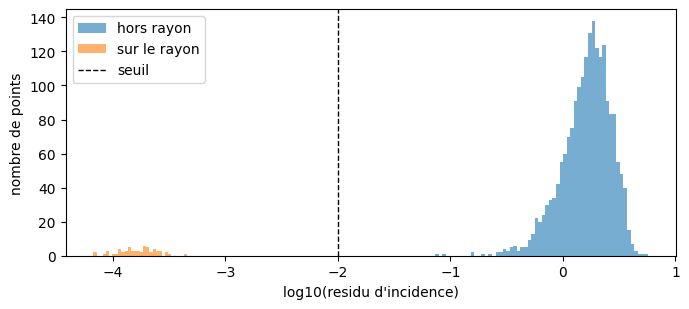

log10 residus : hors-rayon min = -1.14 | sur-rayon max = -3.34


In [6]:
import matplotlib.pyplot as plt

N, M = 2000, 60
cloud = torch.randn(N, 4)
cloud[:, 0] = cloud[:, 0].abs() + 0.5
injected = (P + d.unsqueeze(0) * torch.linspace(-1.5, 1.5, M).unsqueeze(-1)
            + 1e-4 * torch.randn(M, 4))
scene = torch.cat([cloud, injected])
labels = torch.cat([torch.zeros(N), torch.ones(M)])

res = incidence_residual(points_to_hermitian(scene), omega, pi_ray)
thr = 0.01
pred = res < thr
tp = int((pred & labels.bool()).sum())
fp = int((pred & ~labels.bool()).sum())
fn = int((~pred & labels.bool()).sum())
print(f"seuil = {thr} : {tp}/{M} points du rayon detectes, {fp} faux positifs, {fn} manques")

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(res[labels == 0].log10().numpy(), bins=60, alpha=0.6, label="hors rayon")
ax.hist(res[labels == 1].log10().numpy(), bins=30, alpha=0.6, label="sur le rayon")
ax.axvline(math.log10(thr), color="k", ls="--", lw=1, label="seuil")
ax.set_xlabel("log10(residu d'incidence)")
ax.set_ylabel("nombre de points")
ax.legend()
plt.tight_layout()
plt.show()

print("log10 residus : hors-rayon min = %.2f | sur-rayon max = %.2f" %
      (res[labels == 0].min().log10().item(), res[labels == 1].max().log10().item()))

### Lecture du résultat

Les deux populations vivent à des ordres de grandeur différents (typiquement $10^{-4}$ pour les points injectés bruités, $\geq 10^{-2}$ pour le nuage) : le seuil sépare **sans recouvrement** à cette échelle. Deux garde-fous honnêtes : le seuil n'est pas universel (il se règle sur l'échelle de la scène), et la séparabilité vient ici de points injectés **avec bruit** — un point à $10^{-3}$ du rayon est un vrai point hors rayon dont le résidu est petit : le résidu mesure une distance, pas une appartenance binaire.

## 7. Exercices

### Exercice 1 — La carte, vérifiée sur votre propre lot

Rejouez la section 1 sur un lot à vous : hermiticité, déterminant = norme de Minkowski, round-trip.

In [7]:
# Exercice 1 -- a completer
# Indice : reutiliser points_to_hermitian / hermitian_to_points ; tirer t > 0 quelconque
# Etape 1 : tirer un batch (200, 4) avec t positif
# Etape 2 : mesurer max |X - X^dag|, max |det(X) - (t^2 - r^2)|, max |inv(X) - points|
# Etape 3 : imprimer les trois ecarts et les comparer aux tolerances complex64 (~1e-6)
print("Exercice a completer")
resultat = None  # TODO etudiant

Exercice a completer


### Exercice 2 — Le tour complet du double revêtement

Vérifiez sur un lot de points que $U(\theta + 2\pi, \vec n)$ et $U(\theta, \vec n)$ conjuguent **identiquement** alors que leurs matrices sont opposées, et que $U(\theta + 4\pi) = U(\theta)$.

In [8]:
# Exercice 2 -- a completer
# Indice : su2(theta, n) est definie ; comparer via max |.| et conjuguer un petit lot
# Etape 1 : poser U_a = su2(theta, n), U_b = su2(theta + 2*pi, n), verifier |U_a + U_b| ~ 0
# Etape 2 : conjuguer 5 points par U_a puis U_b, verifier que les X' coincident
# Etape 3 : verifier su2(theta + 4*pi, n) - U_a ~ 0 : le tour complet du revetement
print("Exercice a completer")
resultat = None  # TODO etudiant

Exercice a completer


### Exercice 3 — Rayons parallèles : deux twisteurs distincts

Deux rayons de même direction mais de points de passage différents partagent le même $\pi$ et diffèrent par $\omega$. Construisez le rayon 2 passant par $P_2 = P + 0{,}3\,e_\perp$ (même $\pi$), et montrez qu'un point du rayon 1 a un résidu **non nul** sur le rayon 2.

In [9]:
# Exercice 3 -- a completer
# Indice : omega2 = i X_{P2} pi_ray avec P2 = P + 0.3 * e_perp ; reutiliser incidence_residual
# Etape 1 : poser P2 et calculer omega2 = i * (X_{P2} @ pi_ray)
# Etape 2 : evaluer le residu du rayon 2 sur 5 points du rayon 1 (P + s d)
# Etape 3 : evaluer le residu du rayon 2 sur ses propres points (P2 + s d) et comparer
print("Exercice a completer")
resultat = None  # TODO etudiant

Exercice a completer


## Périmètre honnête

- Ce carnet vérifie la structure **classique et numérique** de la correspondance (carte hermitienne, points nuls, SU(2), incidence, noyau de collision) — en `complex64`, donc avec un plancher de résidu $\sim 10^{-7}$ ; toutes les vérifications sont des résidus mesurés, aucune n'est symbolique.
- Ce qu'il **ne couvre pas** : la compactification de l'espace-temps (points à l'infini), l'hélicité, l'espace des twisteurs comme variété, les amplitudes de diffusion — la théorie de Penrose est bien plus grande que son moteur de rendu.
- Les **cinq réserves sur la source** (pose 5 paramètres, nullité forcée 3D, benchmarks XPU non reproductibles, démos non validées, code re-dérivé) sont détaillées en tête de carnet ; la nullité forcée est discutée en section 2.
- Le **rendu** analytique par incidence (nuage → image, comparaison aux champs de radiance) est le **livrable 2** de l'issue #26114 : ce carnet en pose uniquement les maths.

## À retenir

| Notion | Ce qu'elle dit | Où la voir |
|---|---|---|
| Point $\leftrightarrow X^{AA'}$ | hermitienne $2\times 2$ ; $\det X = t^2 - \vec r\,^2$ (norme de Minkowski) | §1 |
| Point nul $=$ spineur | $\det X = 0 \Leftrightarrow$ rang 1 $\Leftrightarrow X = \pi \otimes \bar\pi$, à phase près | §2 |
| SU(2) double revêtement | demi-angles : $U(\theta+2\pi) = -U(\theta)$ conjugue pareil ; $UXU^\dagger$ est la rotation classique | §3 |
| Incidence $\omega = iX\pi$ | résidu nul $\Leftrightarrow$ point **sur le rayon** ; direction portée par $a \perp \pi$ | §4 |
| Loi $(\omega,\pi) \to (U\omega, U\pi)$ | l'incidence est invariante par rotation — mesuré sur 200 SU(2) | §5 |
| Noyau de collision | résidus bimodaux, seuil empirique dépendant de l'échelle de scène | §6 |

## Vérifiez votre compréhension

1. Pourquoi $\det X = t^2 - \vec r\,^2$ suffit-il à affirmer que tout $X = \pi \otimes \bar\pi$ est sur le cône de lumière — et pourquoi la réciproque exige-t-elle *de plus* que $X$ soit hermitienne ?
2. $U(2\pi) = -\mathbb{1}$ conjugue comme l'identité. Qu'est-ce que cela dit de la différence entre $SU(2)$ et $SO(3)$, et pourquoi la phase de $\pi$ (section 2) est-elle le même phénomène ?
3. La direction du rayon portée par un twistor $(\omega, \pi)$ est $a \otimes \bar a$ avec $a \perp \pi$. Si vous remplacez $\pi$ par $e^{i\varphi}\pi$, le rayon change-t-il ?
4. La loi $\pi' = U\pi$ a été dérivée en exigeant que la norme du résidu soit préservée. Quelle étape du raisonnement utilise le fait que $U$ est **unitaire** — et que perdrait-on avec une $SL(2,\mathbb{C})$ quelconque ?

## Pour aller plus loin

- **Carnet précédent** : [Jauge-03 — L'action de Wilson : boucle de Wilson et confinement](Jauge-03-Action-Wilson-Confinement-Python.ipynb) — le même SU(2), mais sur réseau et dans le rôle de jauge.
- **Le pont Jauge-02** : [Jauge-02 — De la symétrie globale à la jauge locale](Jauge-02-Invariance-Jauge-U1-SU2-Python.ipynb) pose SU(2) comme groupe interne ; ce carnet le retrouve comme revêtement des rotations.
- **Suite naturelle** : le **livrable 2** de l'issue #26114 — rendu analytique par incidence contre champ de radiance appris (série [GenAI/3D](../../GenAI/3D/README.md)), mêmes maths, question inverse : *quand une représentation analytique bat-elle un réseau appris ?*
- **Source** : [`isopidi-stack/twistor-render-core`](https://github.com/isopidi-stack/twistor-render-core) (MIT, v0.6.0) — ~25 Ko de code réel, re-dérivé ici, jamais importé.

## Références — copies archivées au gisement

- **Code source** : `isopidi-stack/twistor-render-core`, MIT — étudié et re-dérivé **firsthand** au commit `0a77e74d5d4` (`pyproject.toml` 0.8.0, aucun tag publié au moment du clonage ; clone local du 13/11/2026) ; notice copyright en tête de carnet. Aucune mesure du dépôt reprise sans ré-exécution locale.
- **R. Penrose, *Twistor Theory*** — fond historique de la relation d'incidence. **Non archivé au gisement** au 13/11/2026 : ce carnet ne lui attribue **aucun énoncé ni mesure** ; tout le contenu est re-dérivé du code source et vérifié numériquement.